# Análise de Cancelamento de Clientes (Churn)

**Objetivo:** descobrir *quem cancela* a assinatura e transformar os dados em regras claras que o time de retenção possa usar.

**Base:** `cancelamentos_sample.csv`, com 50.000 registros de clientes (idade, sexo, tipo e duração da assinatura, frequência de uso, ligações ao call center, dias de atraso, total gasto, meses desde a última interação e se o cliente cancelou).

## Principais resultados

- A taxa geral de cancelamento é de **56,7%**.
- Cinco condições simples levam a cancelamento em praticamente 100% dos casos: **contrato mensal**, **mais de 4 ligações ao call center**, **mais de 20 dias de atraso**, **idade acima de 50 anos** e **gasto total abaixo de 500**.
- Juntas, essas regras cobrem 26.632 clientes (54,9% da base), dos quais 99,4% cancelam, e capturam **96,1% de todos os cancelamentos**.
- Quem não cai em nenhuma regra (21.895 clientes) cancela só 4,8%; dentro desse grupo, as mulheres cancelam mais (9,5% contra 2,4% dos homens).
- As regras simples (F1 = 0,979) superam uma regressão logística (F1 = 0,907) e chegam perto de um modelo de Gradient Boosting, quase perfeito. Isso mostra que os padrões da base são muito marcados (veja as ressalvas na seção 7).

### Configuração

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
CAMINHO_DADOS = Path("data/cancelamentos_sample.csv")
PASTA_IMAGENS = Path("images")
PASTA_IMAGENS.mkdir(exist_ok=True)

COR_AZUL, COR_VERMELHO = "#4C78A8", "#E45756"


def fmt_pct(x, casas=1):
    """0.5678 -> '56,8%' (padrão brasileiro)."""
    return f"{x:.{casas}%}".replace(".", ",")


def fmt_int(x):
    """48527 -> '48.527'."""
    return f"{int(x):,}".replace(",", ".")

## 1. Carga e qualidade dos dados



In [ ]:
bruto = pd.read_csv(CAMINHO_DADOS)
print(f"Linhas: {fmt_int(len(bruto))} | Colunas: {bruto.shape[1]}")
bruto.head()

Linhas: 50.000 | Colunas: 12


,CustomerID,idade,sexo,tempo_como_cliente,frequencia_uso,ligacoes_callcenter,dias_atraso,assinatura,duracao_contrato,total_gasto,meses_ultima_interacao,cancelou
0,349936.0,23.0,Male,13.0,22.0,2.0,1.0,Standard,Annual,909.58,23.0,0.0
1,100634.0,49.0,Male,55.0,16.0,3.0,6.0,Premium,Monthly,207.00,29.0,1.0
2,301263.0,30.0,Male,7.0,1.0,0.0,8.0,Basic,Annual,768.78,7.0,0.0
3,119358.0,26.0,Male,40.0,5.0,3.0,8.0,Premium,Annual,398.00,12.0,1.0
4,130955.0,27.0,Female,17.0,30.0,5.0,6.0,Basic,Annual,507.00,15.0,1.0


In [ ]:
qualidade = pd.DataFrame({
    "tipo": bruto.dtypes.astype(str),
    "nulos": bruto.isna().sum(),
    "valores_unicos": bruto.nunique(),
})
display(qualidade)

print(f"Linhas totalmente duplicadas : {bruto.duplicated().sum()}")
print(f"CustomerID repetidos         : {bruto['CustomerID'].duplicated().sum()}")
print(f"Linhas com algum nulo        : {bruto.isna().any(axis=1).sum()}")

bruto.describe().T.round(2)

,tipo,nulos,valores_unicos
CustomerID,float64,0,48531
idade,float64,0,48
sexo,str,3,2
tempo_como_cliente,float64,2,60
frequencia_uso,float64,0,30
ligacoes_callcenter,float64,0,11
dias_atraso,float64,0,31
assinatura,str,0,3
duracao_contrato,str,0,3
total_gasto,float64,0,22488


Linhas totalmente duplicadas : 1469
CustomerID repetidos         : 1469
Linhas com algum nulo        : 4


,count,mean,std,min,25%,50%,75%,max
CustomerID,50000.0,226149.81,129140.88,9.0,114256.25,227891.0,337535.00,449997.0
idade,50000.0,39.33,12.41,18.0,29.00,39.0,48.00,65.0
tempo_como_cliente,49998.0,31.31,17.23,1.0,16.00,32.0,46.00,60.0
frequencia_uso,50000.0,15.82,8.56,1.0,9.00,16.0,23.00,30.0
ligacoes_callcenter,50000.0,3.59,3.06,0.0,1.00,3.0,6.00,10.0
dias_atraso,50000.0,13.02,8.26,0.0,6.00,13.0,19.00,30.0
total_gasto,50000.0,631.76,241.13,100.0,481.00,661.0,830.61,1000.0
meses_ultima_interacao,50000.0,14.51,8.61,1.0,7.00,14.0,22.00,30.0
cancelou,50000.0,0.57,0.50,0.0,0.00,1.0,1.00,1.0


### Decisões de limpeza

- **1.469 linhas são duplicatas exatas**, inclusive no `CustomerID`: o mesmo cliente aparece duas vezes. Removi as repetições.
- **4 linhas com valores ausentes** (`sexo` e `tempo_como_cliente`), menos de 0,01% da base. Removi, porque imputar não compensa para tão poucos casos.
- `CustomerID` é só um identificador e não carrega informação preditiva. Descartei **depois** de checar duplicatas.
- Colunas de contagem vieram como `float` e foram convertidas para inteiro.
- Criei a coluna `status` (Ficou/Cancelou) apenas para rotular os gráficos; ela não entra no modelo.

A limpeza fica numa função para ser reaproveitada e testada.

In [ ]:
COLUNAS_INTEIRAS = [
    "idade", "tempo_como_cliente", "frequencia_uso",
    "ligacoes_callcenter", "dias_atraso", "meses_ultima_interacao",
]


def limpar_dados(bruto: pd.DataFrame) -> pd.DataFrame:
    """Remove duplicados e nulos, descarta o ID e corrige os tipos."""
    df = (
        bruto.drop_duplicates()   # duplicados são idênticos inclusive no CustomerID
             .dropna()
             .drop(columns="CustomerID")
             .reset_index(drop=True)
    )
    df = df.astype({**{c: "int64" for c in COLUNAS_INTEIRAS}, "cancelou": "int64"})
    df["status"] = df["cancelou"].map({0: "Ficou", 1: "Cancelou"})
    return df


df = limpar_dados(bruto)

removidas = len(bruto) - len(df)
print(f"Linhas antes : {fmt_int(len(bruto))}")
print(f"Linhas depois: {fmt_int(len(df))}  (removidas: {fmt_int(removidas)}, {fmt_pct(removidas / len(bruto))})")
df.dtypes

Linhas antes : 50.000
Linhas depois: 48.527  (removidas: 1.473, 2,9%)


idade                       int64
sexo                          str
tempo_como_cliente          int64
frequencia_uso              int64
ligacoes_callcenter         int64
dias_atraso                 int64
assinatura                    str
duracao_contrato              str
total_gasto               float64
meses_ultima_interacao      int64
cancelou                    int64
status                        str
dtype: object

## 2. Visão geral do cancelamento

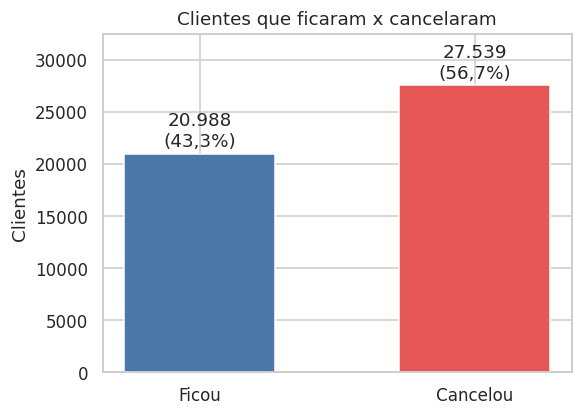

Taxa geral de cancelamento: 56,7%


In [ ]:
taxa_geral = df["cancelou"].mean()
contagem = df["status"].value_counts().reindex(["Ficou", "Cancelou"])

fig, ax = plt.subplots(figsize=(5.5, 4))
barras = ax.bar(contagem.index, contagem.values, color=[COR_AZUL, COR_VERMELHO], width=0.55)
for barra, valor in zip(barras, contagem.values):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 300,
            f"{fmt_int(valor)}\n({fmt_pct(valor / len(df))})", ha="center", va="bottom")
ax.set_ylim(0, contagem.max() * 1.18)
ax.set_title("Clientes que ficaram x cancelaram")
ax.set_ylabel("Clientes")
plt.show()

print(f"Taxa geral de cancelamento: {fmt_pct(taxa_geral)}")

Mais da metade dos clientes (56,7%) cancelou. As classes estão razoavelmente equilibradas, então não preciso de técnicas de balanceamento. Por outro lado, **acertar 56,7% apenas chutando "cancela" para todo mundo é o piso** que qualquer modelo precisa superar.

## 3. Perfil por variáveis categóricas

Taxa de cancelamento dentro de cada categoria. A linha tracejada é a média geral.

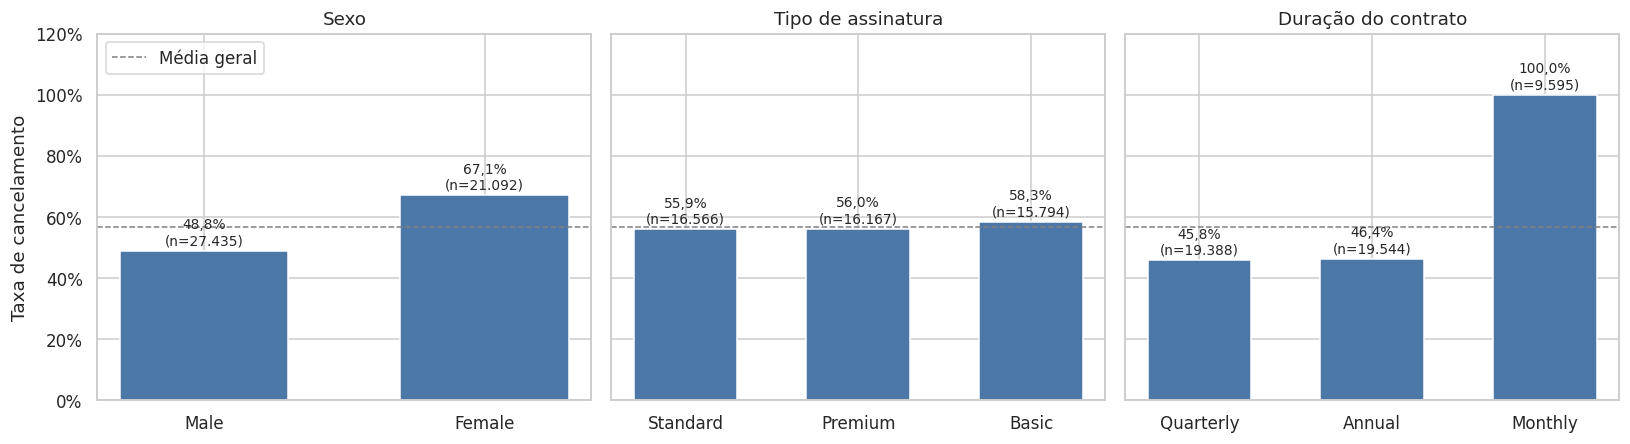

In [ ]:
CATEGORICAS = {
    "sexo": "Sexo",
    "assinatura": "Tipo de assinatura",
    "duracao_contrato": "Duração do contrato",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (coluna, titulo) in zip(axes, CATEGORICAS.items()):
    tabela = df.groupby(coluna)["cancelou"].agg(taxa="mean", clientes="size").sort_values("taxa")
    barras = ax.bar(tabela.index, tabela["taxa"], color=COR_AZUL, width=0.6)
    for barra, taxa, n in zip(barras, tabela["taxa"], tabela["clientes"]):
        ax.text(barra.get_x() + barra.get_width() / 2, taxa + 0.01,
                f"{fmt_pct(taxa)}\n(n={fmt_int(n)})", ha="center", va="bottom", fontsize=9)
    ax.axhline(taxa_geral, ls="--", color="gray", lw=1, label="Média geral")
    ax.set_title(titulo)
    ax.set_ylim(0, 1.2)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Taxa de cancelamento")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

- **Duração do contrato** é a variável mais reveladora: contratos mensais cancelam **100,0%**, enquanto anuais e trimestrais ficam em torno de 46,4% e 45,8%.
- **Sexo:** mulheres cancelam 67,1% contra 48,8% dos homens.
- **Tipo de assinatura** quase não diferencia os clientes (55,9% a 58,3%).

## 4. Perfil por variáveis numéricas

Para cada variável, a taxa de cancelamento por valor (quando há poucos valores distintos) ou por faixa de mesmo tamanho.

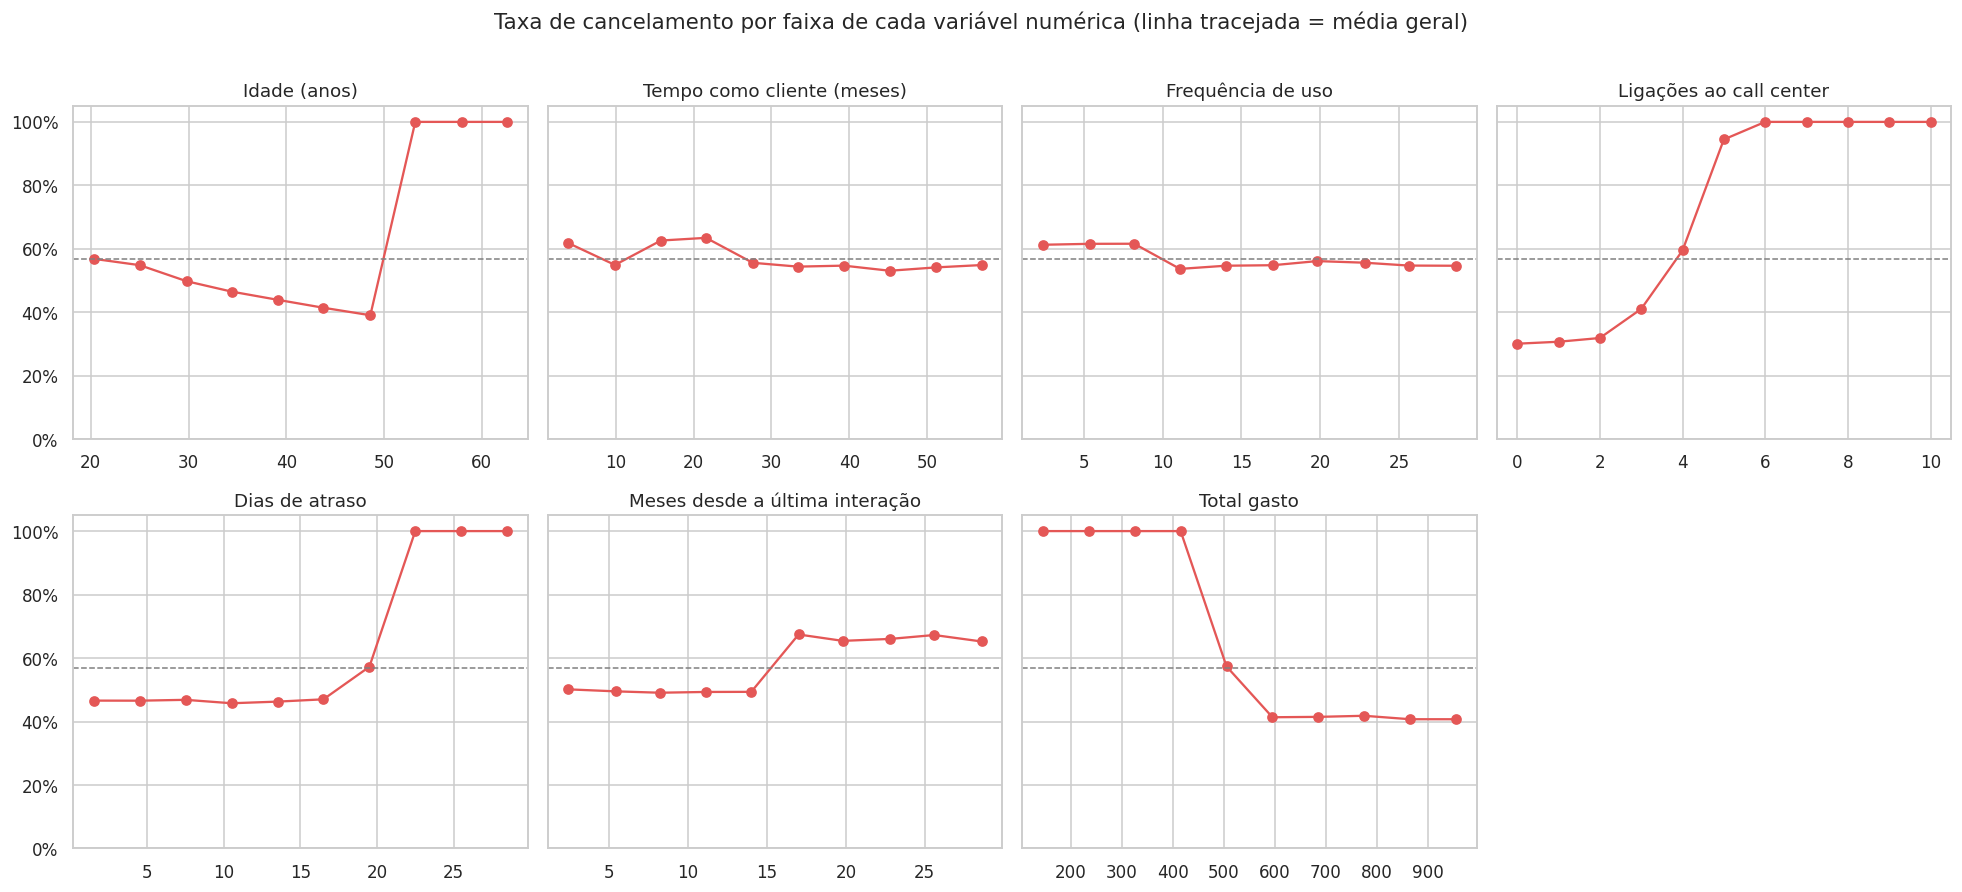

In [ ]:
NUMERICAS = {
    "idade": "Idade (anos)",
    "tempo_como_cliente": "Tempo como cliente (meses)",
    "frequencia_uso": "Frequência de uso",
    "ligacoes_callcenter": "Ligações ao call center",
    "dias_atraso": "Dias de atraso",
    "meses_ultima_interacao": "Meses desde a última interação",
    "total_gasto": "Total gasto",
}


def taxa_por_faixa(df, coluna, n_faixas=10):
    """Taxa de cancelamento por valor (se poucos valores) ou por faixa de mesmo tamanho."""
    if df[coluna].nunique() > 12:
        faixas = pd.cut(df[coluna], bins=n_faixas)
        taxa = df.groupby(faixas, observed=True)["cancelou"].mean()
        taxa.index = [round(intervalo.mid, 1) for intervalo in taxa.index]
    else:
        taxa = df.groupby(coluna)["cancelou"].mean()
    return taxa


fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
axes = axes.ravel()
for ax, (coluna, rotulo) in zip(axes, NUMERICAS.items()):
    taxa = taxa_por_faixa(df, coluna)
    ax.plot(taxa.index, taxa.values, marker="o", color=COR_VERMELHO)
    ax.axhline(taxa_geral, ls="--", color="gray", lw=1)
    ax.set_title(rotulo)
    ax.set_ylim(0, 1.05)
axes[-1].axis("off")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[4].yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle("Taxa de cancelamento por faixa de cada variável numérica (linha tracejada = média geral)",
             y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

- Em **ligações ao call center, dias de atraso, idade e total gasto** o gráfico não é uma curva suave, e sim um **degrau**: a taxa sobe de forma brusca e fica em ~100% a partir de um valor de corte. É o tipo de padrão que dá para virar regra de negócio.
- Entre os clientes de até 50 anos, quanto mais jovem, maior o cancelamento.
- `meses_ultima_interacao` tem efeito moderado: acima de cerca de 15 meses sem interação, a taxa passa de ~50% para ~65%.
- `tempo_como_cliente` e `frequencia_uso` mostram pouca relação com o cancelamento.

## 5. Regras de corte (limiares)

Os degraus acima sugerem limites. Para não escolher números no olho, varro vários cortes para cada variável e observo onde a taxa de cancelamento chega a ~100%.

In [ ]:
def varrer_limiar(df, coluna, limiares, sentido):
    """Taxa de cancelamento do grupo que passa de cada limiar testado."""
    linhas = []
    for t in limiares:
        mascara = df[coluna] > t if sentido == ">" else df[coluna] < t
        linhas.append({
            "limiar": t,
            "clientes": int(mascara.sum()),
            "taxa_cancelamento": round(df.loc[mascara, "cancelou"].mean(), 3),
        })
    return pd.DataFrame(linhas).set_index("limiar")


VARREDURAS = {
    "ligacoes_callcenter > limiar": ("ligacoes_callcenter", range(2, 8), ">"),
    "dias_atraso > limiar":         ("dias_atraso", range(16, 26, 2), ">"),
    "idade > limiar":               ("idade", range(46, 54), ">"),
    "total_gasto < limiar":         ("total_gasto", range(440, 580, 20), "<"),
}

for titulo, (coluna, limiares, sentido) in VARREDURAS.items():
    print(f"\n{titulo}")
    display(varrer_limiar(df, coluna, limiares, sentido))


ligacoes_callcenter > limiar


,clientes,taxa_cancelamento
limiar,,
2,25777,0.796
3,20039,0.906
4,15764,0.990
5,12984,1.000
6,10325,1.000
7,7749,1.000



dias_atraso > limiar


,clientes,taxa_cancelamento
limiar,,
16,16806,0.762
18,13181,0.842
20,9356,1.000
22,7423,1.000
24,5518,1.000



idade > limiar


,clientes,taxa_cancelamento
limiar,,
46,14464,0.765
47,13081,0.802
48,11739,0.845
49,10384,0.906
50,8886,1.000
51,8304,1.000
52,7704,1.000
53,7139,1.000



total_gasto < limiar


,clientes,taxa_cancelamento
limiar,,
440,10823,1.000
460,11474,1.000
480,12074,1.000
500,12741,1.000
520,14187,0.940
540,15597,0.894
560,17005,0.854


A taxa cresce até o limiar e se mantém em ~100% depois dele. Escolhi o **menor corte que preserva a taxa em ~100%**, para cobrir o máximo de clientes:

- ligações ao call center **> 4** (99,0%; com > 5 seriam 100%, mas ganho cobertura com o corte menor);
- dias de atraso **> 20**;
- idade **> 50**;
- total gasto **< 500**.

Agora aplico as cinco regras (as quatro acima mais contrato mensal) e meço o resultado.

In [ ]:
LIMIAR_GASTO = 500

REGRAS = {
    "Contrato mensal":                     df["duracao_contrato"] == "Monthly",
    "Mais de 4 ligações ao call center":   df["ligacoes_callcenter"] > 4,
    "Mais de 20 dias de atraso":           df["dias_atraso"] > 20,
    "Idade acima de 50 anos":              df["idade"] > 50,
    f"Gasto total abaixo de {LIMIAR_GASTO}": df["total_gasto"] < LIMIAR_GASTO,
}

resumo = pd.DataFrame({
    nome: {
        "clientes": int(m.sum()),
        "pct_base": m.mean(),
        "taxa": df.loc[m, "cancelou"].mean(),
    }
    for nome, m in REGRAS.items()
}).T

# visão formatada para leitura
display(resumo.assign(
    clientes=resumo["clientes"].map(fmt_int),
    pct_base=resumo["pct_base"].map(fmt_pct),
    taxa=resumo["taxa"].map(fmt_pct),
).rename(columns={"pct_base": "% da base", "taxa": "taxa de cancelamento"}))

# clientes que caem em pelo menos uma regra
alto_risco = pd.concat(REGRAS.values(), axis=1).any(axis=1)

n_alto, n_rest = int(alto_risco.sum()), int((~alto_risco).sum())
taxa_alto = df.loc[alto_risco, "cancelou"].mean()
taxa_rest = df.loc[~alto_risco, "cancelou"].mean()
captura = df.loc[alto_risco, "cancelou"].sum() / df["cancelou"].sum()

print(f"\nPelo menos uma regra : {fmt_int(n_alto)} clientes ({fmt_pct(n_alto / len(df))}) -> {fmt_pct(taxa_alto)} cancelam")
print(f"Nenhuma regra        : {fmt_int(n_rest)} clientes ({fmt_pct(n_rest / len(df))}) -> {fmt_pct(taxa_rest)} cancelam")
print(f"Cancelamentos capturados pelas regras: {fmt_pct(captura)}")

,clientes,% da base,taxa de cancelamento
Contrato mensal,9.595,"19,8%","100,0%"
Mais de 4 ligações ao call center,15.764,"32,5%","99,0%"
Mais de 20 dias de atraso,9.356,"19,3%","100,0%"
Idade acima de 50 anos,8.886,"18,3%","100,0%"
Gasto total abaixo de 500,12.741,"26,3%","100,0%"



Pelo menos uma regra : 26.632 clientes (54,9%) -> 99,4% cancelam
Nenhuma regra        : 21.895 clientes (45,1%) -> 4,8% cancelam
Cancelamentos capturados pelas regras: 96,1%


- Cada regra isolada atinge de 99,0% a 100% de cancelamento.
- **26.632 clientes (54,9% da base) caem em pelo menos uma regra, e 99,4% deles cancelam.**
- Essas regras capturam **96,1% de todos os cancelamentos**.
- Quem não cai em nenhuma regra tem taxa de apenas **4,8%**.

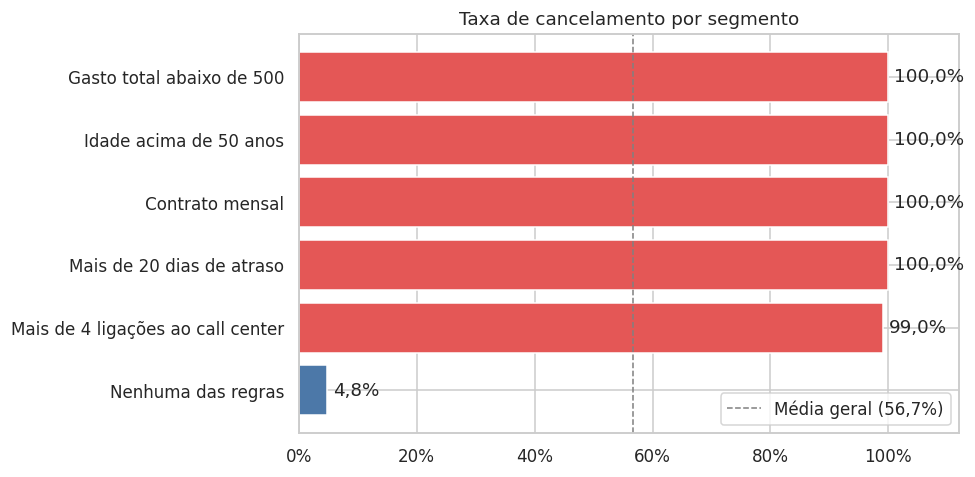

In [ ]:
segmentos = {nome: df.loc[m, "cancelou"].mean() for nome, m in REGRAS.items()}
segmentos["Nenhuma das regras"] = taxa_rest
serie = pd.Series(segmentos).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
cores = [COR_AZUL if nome == "Nenhuma das regras" else COR_VERMELHO for nome in serie.index]
ax.barh(serie.index, serie.values, color=cores)
for y, valor in enumerate(serie.values):
    ax.text(valor + 0.01, y, fmt_pct(valor), va="center")
ax.axvline(taxa_geral, ls="--", color="gray", lw=1, label=f"Média geral ({fmt_pct(taxa_geral)})")
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Taxa de cancelamento por segmento")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(PASTA_IMAGENS / "churn_por_regra.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Clientes fora das regras

O que ainda diferencia quem cancela entre os 21.895 clientes sem nenhum dos cinco gatilhos?

In [ ]:
restante = df.loc[~alto_risco]

for coluna in CATEGORICAS:
    tabela = restante.groupby(coluna)["cancelou"].agg(taxa="mean", clientes="size").round(3)
    print(f"\n{coluna}")
    display(tabela)

print("\nCorrelação com cancelamento (somente clientes sem nenhuma regra):")
corr = restante[list(NUMERICAS)].corrwith(restante["cancelou"]).sort_values().round(3)
corr


sexo


,taxa,clientes
sexo,,
Female,0.095,7621
Male,0.024,14274



assinatura


,taxa,clientes
assinatura,,
Basic,0.056,6915
Premium,0.042,7366
Standard,0.048,7614



duracao_contrato


,taxa,clientes
duracao_contrato,,
Annual,0.046,10897
Quarterly,0.051,10998



Correlação com cancelamento (somente clientes sem nenhuma regra):


idade                    -0.093
frequencia_uso           -0.050
tempo_como_cliente       -0.043
dias_atraso              -0.008
total_gasto              -0.006
meses_ultima_interacao    0.144
ligacoes_callcenter       0.147
dtype: float64

- **Sexo** continua pesando: 9,5% das mulheres cancelam contra 2,4% dos homens.
- **Ligações ao call center** (correlação 0,147) e **meses sem interação** (0,144) são os sinais numéricos mais fortes mesmo abaixo dos cortes, ótimos candidatos a monitoramento contínuo.

## 7. Modelo preditivo de referência

Para dar uma régua de comparação, treino três modelos com divisão 80/20 estratificada. O pré-processamento (padronização e one-hot) fica **dentro do `Pipeline`**, para que nada do conjunto de teste vaze para o treino. Também comparo com as regras da seção 5, sem aprendizado de máquina.

In [ ]:
FEATURES_NUM = list(NUMERICAS)
FEATURES_CAT = list(CATEGORICAS)

X = df[FEATURES_NUM + FEATURES_CAT]
y = df["cancelou"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

preprocessador = ColumnTransformer([
    ("num", StandardScaler(), FEATURES_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURES_CAT),
])

MODELOS = {
    "Baseline (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": LogisticRegression(max_iter=1000),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=SEED),
}


def avaliar(y_real, y_pred, y_score):
    return {
        "AUC": roc_auc_score(y_real, y_score),
        "Acurácia": accuracy_score(y_real, y_pred),
        "Precisão": precision_score(y_real, y_pred, zero_division=0),
        "Recall": recall_score(y_real, y_pred),
        "F1": f1_score(y_real, y_pred),
    }


pipelines, resultados = {}, {}
for nome, estimador in MODELOS.items():
    pipe = Pipeline([("prep", clone(preprocessador)), ("modelo", estimador)])
    pipe.fit(X_train, y_train)
    pipelines[nome] = pipe
    resultados[nome] = avaliar(y_test, pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1])

# comparação com as regras de negócio encontradas na análise exploratória
regra_teste = alto_risco.loc[X_test.index].astype(int)
resultados["Regras de negócio (EDA)"] = avaliar(y_test, regra_teste, regra_teste)

tabela_modelos = pd.DataFrame(resultados).T.round(3)
print(f"Treino: {fmt_int(len(X_train))} clientes | Teste: {fmt_int(len(X_test))} clientes")
tabela_modelos

Treino: 38.821 clientes | Teste: 9.706 clientes


,AUC,Acurácia,Precisão,Recall,F1
Baseline (classe majoritária),0.500,0.567,0.567,1.000,0.724
Regressão logística,0.962,0.896,0.925,0.890,0.907
Gradient Boosting,1.000,0.999,1.000,0.998,0.999
Regras de negócio (EDA),0.978,0.976,0.995,0.963,0.979


Baseline	Acerta 56,7% sempre prevendo "cancela" (AUC 0,500)

Regressão logística	AUC 0,962 e F1 0,907; boa, mas não captura os degraus

Regras de negócio	F1 0,979 sem treinar nada e totalmente explicável

Gradient Boosting	AUC 1,000 e F1 0,999; praticamente perfeito


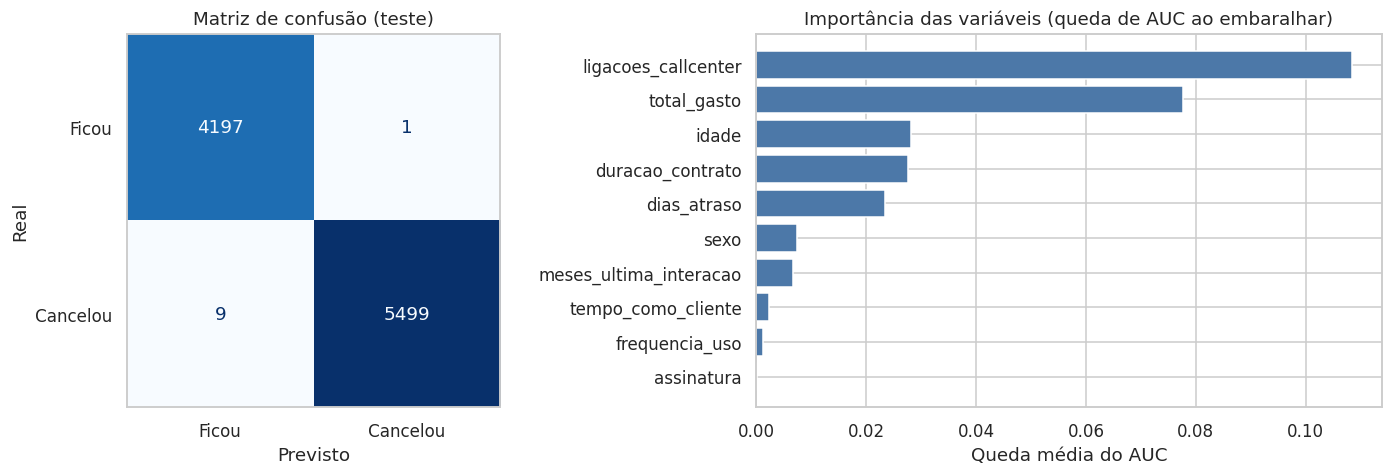

ligacoes_callcenter       0.1084
total_gasto               0.0777
idade                     0.0282
duracao_contrato          0.0275
dias_atraso               0.0233
sexo                      0.0074
meses_ultima_interacao    0.0066
tempo_como_cliente        0.0023
frequencia_uso            0.0012
assinatura                0.0002
dtype: float64

In [ ]:
melhor = pipelines["Gradient Boosting"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})

ConfusionMatrixDisplay.from_estimator(
    melhor, X_test, y_test, display_labels=["Ficou", "Cancelou"],
    cmap="Blues", colorbar=False, ax=axes[0],
)
axes[0].set_title("Matriz de confusão (teste)")
axes[0].set_xlabel("Previsto")
axes[0].set_ylabel("Real")
axes[0].grid(False)

perm = permutation_importance(
    melhor, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1
)
importancia = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
axes[1].barh(importancia.index, importancia.values, color=COR_AZUL)
axes[1].set_title("Importância das variáveis (queda de AUC ao embaralhar)")
axes[1].set_xlabel("Queda média do AUC")

plt.tight_layout()
fig.savefig(PASTA_IMAGENS / "importancia_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

importancia.sort_values(ascending=False).round(4)

As variáveis mais importantes para o modelo são **ligações ao call center**, **total gasto** e **idade**, seguidas de duração do contrato e dias de atraso, o que bate com a análise exploratória. O tipo de assinatura praticamente não contribui.

## 8. Conclusões e recomendações

Contrato mensal	19,8% da base, 100,0% cancelam	Oferecer migração com benefício para plano trimestral ou anual

Mais de 4 ligações ao call center	32,5% da base, 99,0% cancelam	Alerta no CRM e contato proativo da retenção a partir da 3ª ligação

Mais de 20 dias de atraso	19,3% da base, 100,0% cancelam	Régua de cobrança e renegociação antes do 20º dia

Idade acima de 50 anos	18,3% da base, 100,0% cancelam	Pesquisa qualitativa para entender a adequação do produto a esse perfil

Gasto total abaixo de 500	26,3% da base, 100,0% cancelam	Ações de ativação e aumento de uso para clientes de baixo valor

Mulheres fora dos gatilhos	9,5% contra 2,4% dos homens	Investigar causas (preço, atendimento, experiência) antes de agir